# 05 — Model Tuning

## Goal

Notebook 04 ne models compare karke best ML candidate select kiya tha.

Is notebook mein hum:

1. Notebook 04 ke validation results se best ML model identify karenge.
2. Sirf training period ke andar time-series-safe tuning karenge.
3. `RandomizedSearchCV + TimeSeriesSplit` use karenge.
4. Tuned model ko original validation period par check karenge.
5. Improvement hone par **Train + Validation** data par final tuned model fit karenge.
6. Future test period par final evaluation karenge.
7. Tuned best model ko:

`models/best_forecasting_model.joblib`

mein save karenge.

**Important:** Agar ye file pehle se saved hai, new tuned model usko **override** karega.

Random train/test split use nahi hoga.

In [1]:
from pathlib import Path
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# Notebook project ke /notebooks folder ke andar run ho raha ho to root ek level upar hai.
PROJECT_ROOT = (
    Path.cwd().parent
    if Path.cwd().name.lower() == "notebooks"
    else Path.cwd()
)

PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"
ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"
MODELS_DIR = PROJECT_ROOT / "models"

ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

FEATURED_DATA_PATH = PROCESSED_DATA_DIR / "train_featured.csv"
VALIDATION_RESULTS_PATH = ARTIFACTS_DIR / "model_comparison_validation.csv"

if not FEATURED_DATA_PATH.exists():
    raise FileNotFoundError(
        f"Feature dataset not found: {FEATURED_DATA_PATH}. "
        "Run Notebook 03 first."
    )

if not VALIDATION_RESULTS_PATH.exists():
    raise FileNotFoundError(
        f"Notebook 04 validation results not found: {VALIDATION_RESULTS_PATH}. "
        "Run Notebook 04 before running this notebook."
    )

print("Project root:", PROJECT_ROOT)
print("Featured data:", FEATURED_DATA_PATH)
print("Validation results:", VALIDATION_RESULTS_PATH)


Project root: d:\Projects\Revenue Demand Forecasting
Featured data: d:\Projects\Revenue Demand Forecasting\data\processed\train_featured.csv
Validation results: d:\Projects\Revenue Demand Forecasting\artifacts\model_comparison_validation.csv


## 1. Load Featured Dataset and Previous Model Comparison

Notebook 03 se generated `train_featured.csv` use hoga.

Notebook 04 ke `model_comparison_validation.csv` se hum decide karenge ki tuning kis ML model ki karni hai.

In [2]:
df = pd.read_csv(FEATURED_DATA_PATH, parse_dates=["date"])
validation_results = pd.read_csv(VALIDATION_RESULTS_PATH)

df = df.sort_values("date").reset_index(drop=True)

print("Featured dataset shape:", df.shape)
display(validation_results)


Featured dataset shape: (2950992, 35)


,Model,MAE,RMSE,MAPE,R2
0,RandomForest,56.112646,388.373583,54.114066,0.909130
1,XGBoost,60.145061,389.582664,59.457201,0.908563
2,HistGradientBoosting,61.897947,390.950369,52.279632,0.907920
3,Previous Week Baseline,87.615866,569.014729,52.081795,0.804939
4,Previous Day Baseline,120.952726,620.693127,57.178221,0.767899


In [3]:
# Baseline rows ko hata kar sirf ML models dekho.
baseline_names = {
    "Previous Day Baseline",
    "Previous Week Baseline"
}

ml_results = validation_results[
    ~validation_results["Model"].isin(baseline_names)
].copy()

if ml_results.empty:
    raise ValueError("No ML model found in model_comparison_validation.csv.")

ml_results = ml_results.sort_values("MAE").reset_index(drop=True)

best_candidate_name = ml_results.iloc[0]["Model"]

print("Best ML candidate from Notebook 04:", best_candidate_name)


Best ML candidate from Notebook 04: RandomForest


## 2. Same Chronological Train / Validation / Test Split

Exactly Notebook 04 ki tarah date-based split rakhenge:

- 70% dates → Train
- next 15% dates → Validation
- last 15% dates → Test

Future data training mein nahi jayega.

In [4]:
unique_dates = sorted(df["date"].dropna().unique())

train_end = int(len(unique_dates) * 0.70)
validation_end = int(len(unique_dates) * 0.85)

train_dates = unique_dates[:train_end]
validation_dates = unique_dates[train_end:validation_end]
test_dates = unique_dates[validation_end:]

train_df = df[df["date"].isin(train_dates)].copy()
validation_df = df[df["date"].isin(validation_dates)].copy()
test_df = df[df["date"].isin(test_dates)].copy()

print("Train:", train_df.shape)
print("Validation:", validation_df.shape)
print("Test:", test_df.shape)

print("\nDate ranges:")
print("Train:", train_df["date"].min(), "to", train_df["date"].max())
print("Validation:", validation_df["date"].min(), "to", validation_df["date"].max())
print("Test:", test_df["date"].min(), "to", test_df["date"].max())


Train: (2065338, 35)
Validation: (441936, 35)
Test: (443718, 35)

Date ranges:
Train: 2013-01-29 00:00:00 to 2016-04-04 00:00:00
Validation: 2016-04-05 00:00:00 to 2016-12-08 00:00:00
Test: 2016-12-09 00:00:00 to 2017-08-15 00:00:00


## 3. Prepare Features

Same preprocessing approach use karenge jo Notebook 04 mein use hua tha.

`date` aur target `sales` model ko directly nahi denge.

Categorical columns ko `OrdinalEncoder` se encode karenge.

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.pipeline import Pipeline

TARGET = "sales"

DROP_COLUMNS = [
    TARGET,
    "date",
    "holiday_types",
]

X_train = train_df.drop(columns=DROP_COLUMNS, errors="ignore")
y_train = train_df[TARGET]

X_validation = validation_df.drop(columns=DROP_COLUMNS, errors="ignore")
y_validation = validation_df[TARGET]

X_test = test_df.drop(columns=DROP_COLUMNS, errors="ignore")
y_test = test_df[TARGET]

X_train_validation = pd.concat(
    [X_train, X_validation],
    axis=0,
    ignore_index=True
)

y_train_validation = pd.concat(
    [y_train, y_validation],
    axis=0,
    ignore_index=True
)

categorical_columns = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numeric_columns = X_train.select_dtypes(
    exclude=["object", "category"]
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    (
        "encoder",
        OrdinalEncoder(
            handle_unknown="use_encoded_value",
            unknown_value=-1
        )
    )
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_columns),
    ("categorical", categorical_pipeline, categorical_columns),
])

print("Numeric features:", len(numeric_columns))
print("Categorical features:", categorical_columns)


Numeric features: 28
Categorical features: ['family', 'city', 'state', 'type']


## 4. Choose the Tuning Data

Store Sales dataset bahut bada hai, isliye tuning ke liye training period ka recent chronological portion use karenge.

Important:

- sirf **training period** se tuning hogi
- validation aur test data tuning ko nahi diya jayega
- row order preserve rahega
- final tuned model ko baad mein Train + Validation par fit karenge

Isse tuning practical bhi rahegi aur future leakage bhi nahi hoga.

In [6]:
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV

# Tuning ko practical rakhne ke liye training period ka recent chronological window.
# Isse future validation/test data touch nahi hota.
MAX_TUNING_ROWS = 300_000

if len(X_train) > MAX_TUNING_ROWS:
    tuning_start = len(X_train) - MAX_TUNING_ROWS
    X_tune = X_train.iloc[tuning_start:].copy()
    y_tune = y_train.iloc[tuning_start:].copy()
else:
    X_tune = X_train.copy()
    y_tune = y_train.copy()

print("Tuning rows:", len(X_tune))
print("Tuning date range:",
      train_df.iloc[-len(X_tune)]["date"],
      "to",
      train_df.iloc[-1]["date"])


Tuning rows: 300000
Tuning date range: 2015-10-18 00:00:00 to 2016-04-04 00:00:00


## 5. Define the Model and Hyperparameter Search Space

Notebook 04 mein jo **best ML model** mila tha, hum usi model ko tune karenge.

Possible models:

- XGBoost
- HistGradientBoosting
- RandomForest

`RandomizedSearchCV` ka scoring metric **MAE** hai, kyunki model selection bhi validation MAE par hua tha.

In [7]:
# Notebook 04 ke best ML model ke according tuning search space select karenge.

if best_candidate_name == "XGBoost":
    try:
        from xgboost import XGBRegressor

        model_to_tune = XGBRegressor(
            objective="reg:squarederror",
            tree_method="hist",
            n_jobs=-1,
            random_state=42
        )

        param_distributions = {
            "model__n_estimators": [300, 500, 700],
            "model__learning_rate": [0.03, 0.05, 0.08, 0.10],
            "model__max_depth": [5, 7, 9],
            "model__min_child_weight": [1, 3, 5],
            "model__subsample": [0.7, 0.8, 0.9, 1.0],
            "model__colsample_bytree": [0.7, 0.8, 0.9, 1.0],
        }

        tuning_model_name = "XGBoost"
        n_iter = 12

    except ImportError:
        raise ImportError(
            "Notebook 04 ka best model XGBoost hai, lekin xgboost installed nahi hai. "
            "Run: pip install xgboost"
        )

elif best_candidate_name == "HistGradientBoosting":
    from sklearn.ensemble import HistGradientBoostingRegressor

    model_to_tune = HistGradientBoostingRegressor(
        random_state=42
    )

    param_distributions = {
        "model__learning_rate": [0.03, 0.05, 0.08, 0.10],
        "model__max_iter": [200, 300, 400, 500],
        "model__max_leaf_nodes": [15, 31, 63],
        "model__min_samples_leaf": [20, 50, 100],
        "model__l2_regularization": [0.0, 0.5, 1.0, 2.0],
    }

    tuning_model_name = "HistGradientBoosting"
    n_iter = 12

elif best_candidate_name == "RandomForest":
    from sklearn.ensemble import RandomForestRegressor

    model_to_tune = RandomForestRegressor(
        n_jobs=-1,
        random_state=42
    )

    param_distributions = {
        "model__n_estimators": [100, 150, 200],
        "model__max_depth": [12, 16, 20, None],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf": [1, 2, 4],
        "model__max_features": ["sqrt", 0.7, 1.0],
    }

    tuning_model_name = "RandomForest"
    n_iter = 8

else:
    raise ValueError(
        f"Unsupported model from Notebook 04: {best_candidate_name}"
    )

tuning_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", model_to_tune)
])

print("Model selected for tuning:", tuning_model_name)
print("Randomized search iterations:", n_iter)


Model selected for tuning: RandomForest
Randomized search iterations: 8


## 6. Time-Series-Safe Hyperparameter Tuning

`TimeSeriesSplit` mein validation fold hamesha future side par hota hai.

Example:

`Past → Train`

`Later Past → Validation`

Phir next fold mein training window aur aage badhti hai.

Isliye normal random K-Fold ki jagah time-aware validation use kar rahe hain.

In [8]:
time_split = TimeSeriesSplit(n_splits=3)

random_search = RandomizedSearchCV(
    estimator=tuning_pipeline,
    param_distributions=param_distributions,
    n_iter=n_iter,
    scoring="neg_mean_absolute_error",
    cv=time_split,
    random_state=42,
    n_jobs=-1,
    verbose=2,
    return_train_score=False
)

print("Tuning started...")
print("This can take time on the full Store Sales dataset.")

random_search.fit(X_tune, y_tune)

print("\nTuning completed.")
print("Best CV MAE:", -random_search.best_score_)
print("Best parameters:")
for parameter, value in random_search.best_params_.items():
    print(f"{parameter}: {value}")


Tuning started...
This can take time on the full Store Sales dataset.
Fitting 3 folds for each of 8 candidates, totalling 24 fits

Tuning completed.
Best CV MAE: 75.73435774122605
Best parameters:
model__n_estimators: 100
model__min_samples_split: 2
model__min_samples_leaf: 4
model__max_features: sqrt
model__max_depth: 20


## 7. Check Tuned Model on the Original Validation Period

Yahan validation set abhi bhi untouched hai.

Hum dekhenge ki tuned model, Notebook 04 ke old best candidate se better perform karta hai ya nahi.

In [9]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def calculate_metrics(actual, predicted):
    actual = np.asarray(actual)
    predicted = np.asarray(predicted)

    non_zero = actual != 0

    mape = (
        np.mean(
            np.abs(
                (actual[non_zero] - predicted[non_zero])
                / actual[non_zero]
            )
        ) * 100
        if non_zero.any()
        else 0
    )

    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "MAPE": mape,
        "R2": r2_score(actual, predicted),
    }

tuned_validation_prediction = random_search.best_estimator_.predict(X_validation)

tuned_validation_metrics = calculate_metrics(
    y_validation,
    tuned_validation_prediction
)

print("Tuned model validation metrics:")
display(
    pd.DataFrame(
        [tuned_validation_metrics],
        index=[f"Tuned {tuning_model_name}"]
    )
)


Tuned model validation metrics:


,MAE,RMSE,MAPE,R2
Tuned RandomForest,65.148384,395.48449,46.703592,0.905772


In [10]:
# Notebook 04 ke best ML candidate ka MAE.
old_best_row = ml_results.iloc[0]

old_best_mae = float(old_best_row["MAE"])
tuned_validation_mae = float(tuned_validation_metrics["MAE"])

validation_comparison = pd.DataFrame([
    {
        "Model": f"Previous Best - {best_candidate_name}",
        **old_best_row.drop(labels=["Model"]).to_dict()
    },
    {
        "Model": f"Tuned - {tuning_model_name}",
        **tuned_validation_metrics
    }
])

display(validation_comparison.sort_values("MAE").reset_index(drop=True))

if tuned_validation_mae < old_best_mae:
    print("Tuned model improved validation MAE.")
else:
    print(
        "Tuned model did not improve validation MAE over the previous best candidate."
    )


,Model,MAE,RMSE,MAPE,R2
0,Previous Best - RandomForest,56.112646,388.373583,54.114066,0.909130
1,Tuned - RandomForest,65.148384,395.484490,46.703592,0.905772


Tuned model did not improve validation MAE over the previous best candidate.


## 8. Select the Final Model

Ab do possibilities hain:

**Case 1:** Tuned model ki validation MAE better hai  
→ tuned model ko final model banayenge.

**Case 2:** Tuned model better nahi hai  
→ Notebook 04 ka existing best model retain karenge.

Iska matlab final saved model hamesha validation ke basis par **better model** hoga.

In [11]:
# Existing saved model ko yahan load nahi karenge.
# Reason: joblib/scikit-learn models ko same package versions ke saath load karna safest hai.
# Notebook 04 ke saved validation metrics ko previous-best reference ke liye use karenge.

old_best_row = ml_results.iloc[0]

old_best_mae = float(old_best_row["MAE"])
old_best_name = str(old_best_row["Model"])

tuned_validation_prediction = random_search.best_estimator_.predict(X_validation)

tuned_validation_metrics = calculate_metrics(
    y_validation,
    tuned_validation_prediction
)

print("Previous best model from Notebook 04:")
display(pd.DataFrame([old_best_row]))

print("Tuned model validation metrics:")
display(
    pd.DataFrame(
        [tuned_validation_metrics],
        index=[f"Tuned {tuning_model_name}"]
    )
)

tuned_validation_mae = float(tuned_validation_metrics["MAE"])

if tuned_validation_mae < old_best_mae:
    selected_model_source = "tuned"
    print("✅ Tuned model has better validation MAE.")
    print("It will replace the previous saved model.")
else:
    selected_model_source = "previous"
    print("ℹ️ Tuned model did not improve validation MAE.")
    print("The existing saved model will be left unchanged.")


Previous best model from Notebook 04:


,Model,MAE,RMSE,MAPE,R2
0,RandomForest,56.112646,388.373583,54.114066,0.90913


Tuned model validation metrics:


,MAE,RMSE,MAPE,R2
Tuned RandomForest,65.148384,395.48449,46.703592,0.905772


ℹ️ Tuned model did not improve validation MAE.
The existing saved model will be left unchanged.


## 9. Final Fit and Future Test Evaluation

Agar tuned model better hai, usko **Train + Validation** ke complete development data par fit karenge.

Agar old model better hai, existing model ko final model rakhenge.

Uske baad sirf ek baar future Test period par final evaluation karenge.

In [12]:
# Tuned model ko Train + Validation par fit karenge.
# Test data ko abhi tak tuning mein use nahi kiya gaya.

print("Fitting tuned model on Train + Validation...")
tuned_final_model = random_search.best_estimator_
tuned_final_model.fit(X_train_validation, y_train_validation)
print("Tuned model fitting completed.")

tuned_test_prediction = tuned_final_model.predict(X_test)
tuned_test_prediction = np.clip(tuned_test_prediction, 0, None)

tuned_test_metrics = calculate_metrics(
    y_test,
    tuned_test_prediction
)

print("Tuned model test metrics:")
display(
    pd.DataFrame(
        [tuned_test_metrics],
        index=[f"Tuned {tuning_model_name}"]
    )
)

final_test_metrics = tuned_test_metrics
final_model_name = f"Tuned {tuning_model_name}"


Fitting tuned model on Train + Validation...
Tuned model fitting completed.
Tuned model test metrics:


,MAE,RMSE,MAPE,R2
Tuned RandomForest,67.087587,270.834119,47.44894,0.961316


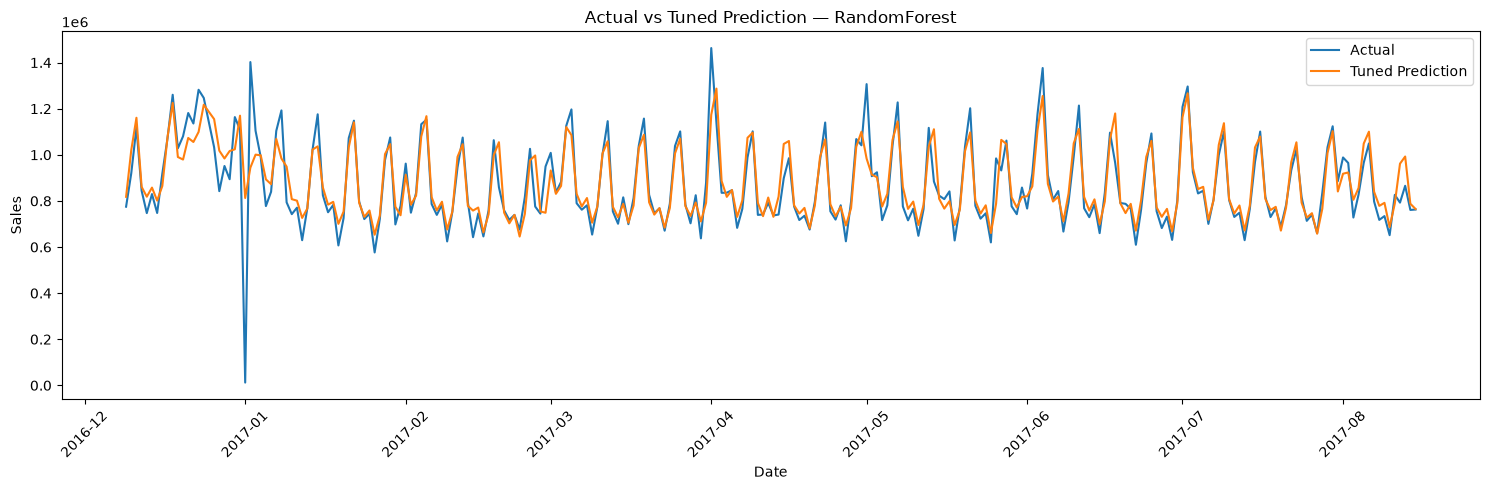

In [13]:
comparison = pd.DataFrame({
    "date": test_df["date"].values,
    "actual": y_test.values,
    "predicted": tuned_test_prediction
})

daily_comparison = (
    comparison
    .groupby("date", as_index=False)
    .agg(
        actual=("actual", "sum"),
        predicted=("predicted", "sum")
    )
)

plt.figure(figsize=(15, 5))
plt.plot(
    daily_comparison["date"],
    daily_comparison["actual"],
    label="Actual"
)
plt.plot(
    daily_comparison["date"],
    daily_comparison["predicted"],
    label="Tuned Prediction"
)
plt.title(f"Actual vs Tuned Prediction — {tuning_model_name}")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 10. Save the Best Final Model

Production ke liye hum same file use karenge:

`models/best_forecasting_model.joblib`

Agar tuned model better hai, old model **override** hoga.

Agar tuned model better nahi hai, existing best model ko simply retain karenge.

Saath mein tuning results aur final metrics save honge.

In [14]:
# Tuning results
tuning_results = pd.DataFrame(random_search.cv_results_)
tuning_results["mean_test_MAE"] = -tuning_results["mean_test_score"]

tuning_results = tuning_results.sort_values(
    "mean_test_MAE"
).reset_index(drop=True)

tuning_results.to_csv(
    ARTIFACTS_DIR / "model_tuning_results.csv",
    index=False
)

# Validation comparison
validation_comparison = pd.DataFrame([
    {
        "Model": old_best_name,
        "MAE": old_best_row["MAE"],
        "RMSE": old_best_row["RMSE"],
        "MAPE": old_best_row["MAPE"],
        "R2": old_best_row["R2"],
    },
    {
        "Model": f"Tuned {tuning_model_name}",
        **tuned_validation_metrics
    }
]).sort_values("MAE").reset_index(drop=True)

validation_comparison.to_csv(
    ARTIFACTS_DIR / "tuned_validation_comparison.csv",
    index=False
)

# Tuned test metrics
pd.DataFrame(
    [tuned_test_metrics],
    index=[f"Tuned {tuning_model_name}"]
).to_csv(
    ARTIFACTS_DIR / "tuned_final_test_metrics.csv"
)

# Save only when tuning improved validation MAE.
MODEL_PATH = MODELS_DIR / "best_forecasting_model.joblib"

if selected_model_source == "tuned":
    old_model_exists = MODEL_PATH.exists()

    joblib.dump(
        tuned_final_model,
        MODEL_PATH
    )

    print("✅ Tuned model saved:")
    print(MODEL_PATH)

    if old_model_exists:
        print("✅ Existing best_forecasting_model.joblib was OVERWRITTEN.")
    else:
        print("✅ New best_forecasting_model.joblib created.")

else:
    print("ℹ️ Existing best_forecasting_model.joblib was NOT changed.")
    print("Reason: tuned validation MAE was not better.")

print("\nSaved artifacts:")
print(ARTIFACTS_DIR / "model_tuning_results.csv")
print(ARTIFACTS_DIR / "tuned_validation_comparison.csv")
print(ARTIFACTS_DIR / "tuned_final_test_metrics.csv")


ℹ️ Existing best_forecasting_model.joblib was NOT changed.
Reason: tuned validation MAE was not better.

Saved artifacts:
d:\Projects\Revenue Demand Forecasting\artifacts\model_tuning_results.csv
d:\Projects\Revenue Demand Forecasting\artifacts\tuned_validation_comparison.csv
d:\Projects\Revenue Demand Forecasting\artifacts\tuned_final_test_metrics.csv


## Tuning Conclusion

Is notebook mein:

- Notebook 04 ka best ML model reference liya gaya
- time-series-safe hyperparameter tuning hui
- `RandomizedSearchCV + TimeSeriesSplit` use hua
- tuned model ko original validation period par evaluate kiya gaya
- tuned model ko Train + Validation par final fit kiya gaya
- future Test period par final evaluation hui
- tuned model ki validation MAE better hone par:
  `models/best_forecasting_model.joblib`
  **override** hua
- better na hone par existing saved model untouched raha

> Note: Existing `.joblib` model ko Notebook 05 mein reload nahi kiya gaya, kyunki scikit-learn serialized models ko training environment ke matching package versions ke saath load karna recommended hai.